# 5C. Transfer Learning - Fashion MNIST (MobileNetV2)
Upscale 28x28 gray -> 32x32 RGB inside the model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
train = pd.read_csv("../datasets/FNN and CNN/Fashion MNIST/fashion-mnist_train.csv")
test = pd.read_csv("../datasets/FNN and CNN/Fashion MNIST/fashion-mnist_test.csv")

y_train = train["label"].to_numpy()
y_test = test["label"].to_numpy()
x_train = train.drop(columns="label").to_numpy().reshape(-1, 28, 28, 1)
x_test = test.drop(columns="label").to_numpy().reshape(-1, 28, 28, 1)

# subsample to keep it fast
x_train = x_train[:10000]
y_train = y_train[:10000]
x_test = x_test[:2000]
y_test = y_test[:2000]

print(x_train.shape)

(10000, 28, 28, 1)


In [3]:
base = keras.applications.MobileNetV2(include_top=False, input_shape=(32, 32, 3), alpha=0.35)
base.trainable = False

inputs = keras.Input(shape=(28, 28, 1))
x = layers.Resizing(32, 32)(inputs)
x = layers.Concatenate()([x, x, x])
x = layers.Rescaling(1./127.5, offset=-1)(x)
x = base(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

/var/folders/r0/_9rxdrf50qx7twh2z0g5921w0000gn/T/ipykernel_95449/1150300068.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = keras.applications.MobileNetV2(include_top=False, input_shape=(32, 32, 3), alpha=0.35)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing (Resizing) │ (None, 32, 32, 1) │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32, 3) │          0 │ resizing[0][0],   │
│ (Concatenate)       │                   │            │ resizing[0][0],   │
│                     │                   │            │ resizing[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 32, 32, 3) │          0 │ concatenate[0][0] │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_0.35_2… │ (None, 1, 1,      │    410,208 │ rescaling[0][0]   │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_0.35… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     81,984 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │        650 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 492,842 (1.88 MB)

 Trainable params: 82,634 (322.79 KB)

 Non-trainable params: 410,208 (1.56 MB)

In [4]:
history = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=3)

Epoch 1/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6300 - loss: 1.2718 - val_accuracy: 0.6920 - val_loss: 0.9096
Epoch 2/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7226 - loss: 0.8179 - val_accuracy: 0.7180 - val_loss: 0.8059
Epoch 3/3
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7441 - loss: 0.7429 - val_accuracy: 0.7280 - val_loss: 0.7855


In [5]:
loss, acc = model.evaluate(x_test, y_test)
print(f"test acc: {acc:.4f}")

 1/63 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6562 - loss: 0.9779

12/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7005 - loss: 0.7801

23/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7405 - loss: 0.7260

34/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7426 - loss: 0.7316

45/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7333 - loss: 0.7744

56/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7338 - loss: 0.7743

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7280 - loss: 0.7855


test acc: 0.7280


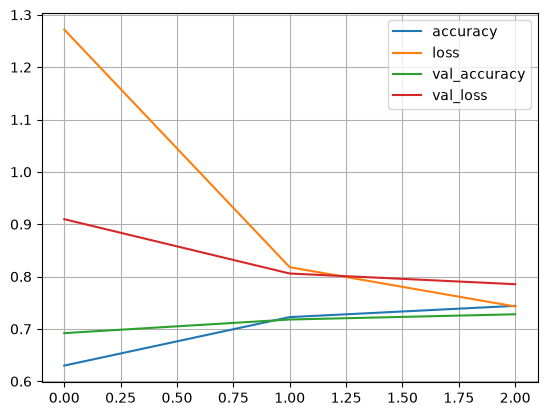

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()